### Reading files

In [3]:
import pandas as pd

try:
    df = pd.read_json('../data/Cell_Phones_and_Accessories_5.json', lines=True)
except ValueError:
    df = pd.read_json('../data/Cell_Phones_and_Accessories_5.json')

print("First 5 rows:")
print(df.head())

df.to_csv('../data/product_reviews.csv', index=False, encoding='utf-8')

df = pd.read_csv('../data/product_reviews.csv')

print("\nDone! The file 'product_reviews.csv' is ready.")

First 5 rows:
       reviewerID        asin      reviewerName helpful  \
0  A30TL5EWN6DFXT  120401325X         christina  [0, 0]   
1   ASY55RVNIL0UD  120401325X          emily l.  [0, 0]   
2  A2TMXE2AFO7ONB  120401325X             Erica  [0, 0]   
3   AWJ0WZQYMYFQ4  120401325X                JM  [4, 4]   
4   ATX7CZYFXI1KW  120401325X  patrice m rogoza  [2, 3]   

                                          reviewText  overall  \
0  They look good and stick good! I just don't li...        4   
1  These stickers work like the review says they ...        5   
2  These are awesome and make my phone look so st...        5   
3  Item arrived in great time and was in perfect ...        4   
4  awesome! stays on, and looks great. can be use...        5   

                                     summary  unixReviewTime   reviewTime  
0                                 Looks Good      1400630400  05 21, 2014  
1                      Really great product.      1389657600  01 14, 2014  
2           

### Data Preprocessing

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 194439 entries, 0 to 194438
Data columns (total 9 columns):
 #   Column          Non-Null Count   Dtype 
---  ------          --------------   ----- 
 0   reviewerID      194439 non-null  object
 1   asin            194439 non-null  object
 2   reviewerName    190914 non-null  object
 3   helpful         194439 non-null  object
 4   reviewText      194340 non-null  object
 5   overall         194439 non-null  int64 
 6   summary         194438 non-null  object
 7   unixReviewTime  194439 non-null  int64 
 8   reviewTime      194439 non-null  object
dtypes: int64(2), object(7)
memory usage: 13.4+ MB


In [6]:
df = df[['asin','reviewText','overall']]
df.isna().sum()

asin           0
reviewText    99
overall        0
dtype: int64

In [7]:
df.dropna(inplace=True)
df.isna().sum()

asin          0
reviewText    0
overall       0
dtype: int64

In [8]:
import nltk
import re
from nltk.corpus import stopwords

nltk.download('stopwords')

stop_words = set(stopwords.words('english'))

def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)  
    words = text.split()
    words = [w for w in words if w not in stop_words]
    return " ".join(words)

df['clean_review'] = df['reviewText'].apply(clean_text)

print(df[['reviewText','clean_review']].head())

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


                                          reviewText  \
0  They look good and stick good! I just don't li...   
1  These stickers work like the review says they ...   
2  These are awesome and make my phone look so st...   
3  Item arrived in great time and was in perfect ...   
4  awesome! stays on, and looks great. can be use...   

                                        clean_review  
0  look good stick good dont like rounded shape a...  
1  stickers work like review says stick great sta...  
2  awesome make phone look stylish used one far a...  
3  item arrived great time perfect condition howe...  
4  awesome stays looks great used multiple apple ...  


### binary sentiment

In [13]:
df = df[df['overall'] != 3]

df['sentiment'] = df['overall'].apply(lambda x: 1 if x > 3 else 0)

df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
Index: 172904 entries, 0 to 194438
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   asin          172904 non-null  object
 1   reviewText    172904 non-null  object
 2   overall       172904 non-null  int64 
 3   clean_review  172904 non-null  object
 4   sentiment     172904 non-null  int64 
dtypes: int64(2), object(3)
memory usage: 7.9+ MB


,asin,reviewText,overall,clean_review,sentiment
0,120401325X,They look good and stick good! I just don't li...,4,look good stick good dont like rounded shape a...,1
1,120401325X,These stickers work like the review says they ...,5,stickers work like review says stick great sta...,1
2,120401325X,These are awesome and make my phone look so st...,5,awesome make phone look stylish used one far a...,1
3,120401325X,Item arrived in great time and was in perfect ...,4,item arrived great time perfect condition howe...,1
4,120401325X,"awesome! stays on, and looks great. can be use...",5,awesome stays looks great used multiple apple ...,1


### Vectorization

In [17]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(max_features=5000)

X = vectorizer.fit_transform(df['clean_review'])
y = df['sentiment']

### Model training

In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## For more balanced analysis

In [27]:
from sklearn.linear_model import LogisticRegression

blr_model = LogisticRegression(class_weight='balanced')

blr_model.fit(X_train, y_train)



,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :ter

### Model Evaluation

In [28]:
from sklearn.metrics import accuracy_score, classification_report

blr_pred = blr_model.predict(X_test)

print("Balanced Logistic Regression Accuracy:", accuracy_score(y_test, blr_pred))
print(classification_report(y_test, blr_pred))

Balanced Logistic Regression Accuracy: 0.87938463318007
              precision    recall  f1-score   support

           0       0.55      0.87      0.67      4901
           1       0.98      0.88      0.93     29680

    accuracy                           0.88     34581
   macro avg       0.76      0.87      0.80     34581
weighted avg       0.91      0.88      0.89     34581



## For more Accurate analysis

In [29]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression()

lr_model.fit(X_train, y_train)



,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

### Model Evaluation

In [30]:
from sklearn.metrics import accuracy_score, classification_report

lr_pred = lr_model.predict(X_test)

print("Logistic Regression Accuracy:", accuracy_score(y_test, lr_pred))
print(classification_report(y_test, lr_pred))

Logistic Regression Accuracy: 0.9234839941008068
              precision    recall  f1-score   support

           0       0.82      0.59      0.68      4901
           1       0.93      0.98      0.96     29680

    accuracy                           0.92     34581
   macro avg       0.88      0.78      0.82     34581
weighted avg       0.92      0.92      0.92     34581



## Naive Bayes

In [31]:
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()

nb_model.fit(X_train, y_train)

nb_pred = nb_model.predict(X_test)

print("Naive Bayes Accuracy:", accuracy_score(y_test, nb_pred))
print(classification_report(y_test, nb_pred))

Naive Bayes Accuracy: 0.8840982042161881
              precision    recall  f1-score   support

           0       0.94      0.20      0.32      4901
           1       0.88      1.00      0.94     29680

    accuracy                           0.88     34581
   macro avg       0.91      0.60      0.63     34581
weighted avg       0.89      0.88      0.85     34581



## Comparison

In [32]:
import pandas as pd

results = {
    "Model": ["Balanced Logistic Regression", "Logistic Regression", "Naive Bayes"],
    "Accuracy": [
        accuracy_score(y_test, blr_pred),
        accuracy_score(y_test, lr_pred),
        accuracy_score(y_test, nb_pred)
    ]
}

comparison = pd.DataFrame(results)

print(comparison)

                          Model  Accuracy
0  Balanced Logistic Regression  0.879385
1           Logistic Regression  0.923484
2                   Naive Bayes  0.884098


## Most important words

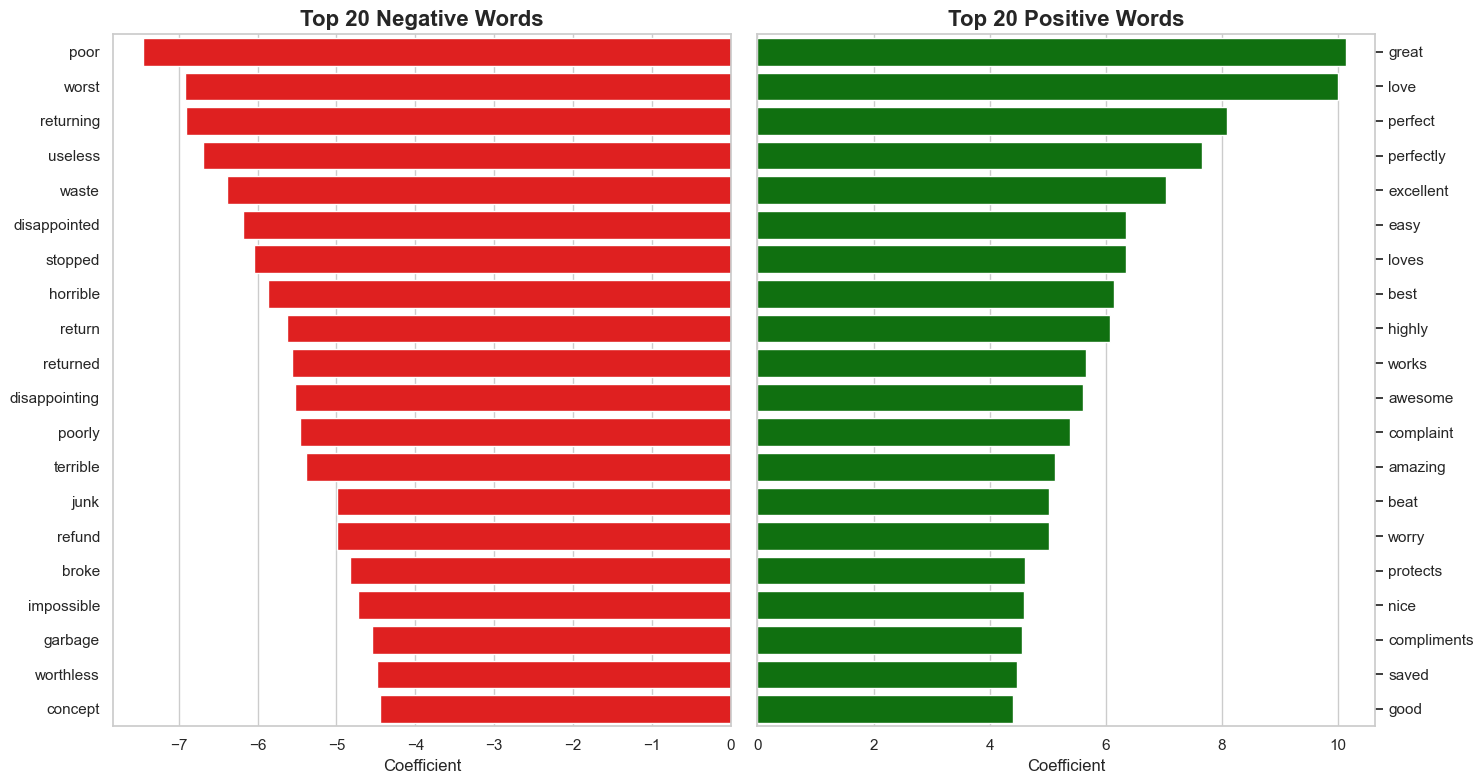

In [54]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

top_positive_idx = np.argsort(coefficients)[-20:]
top_negative_idx = np.argsort(coefficients)[:20]

top_positive = pd.DataFrame({
    'word': feature_names[top_positive_idx],
    'coefficient': coefficients[top_positive_idx]
})

top_negative = pd.DataFrame({
    'word': feature_names[top_negative_idx],
    'coefficient': coefficients[top_negative_idx]
})

sns.set(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(15, 8))

sns.barplot(x='coefficient', y='word', data=top_negative.sort_values('coefficient', ascending=True), color='red', ax=axes[0])
axes[0].set_title("Top 20 Negative Words", fontsize=16, fontweight='bold')
axes[0].set_xlabel("Coefficient")
axes[0].set_ylabel("")

sns.barplot(x='coefficient', y='word', data=top_positive.sort_values('coefficient', ascending=False), color='green', ax=axes[1])
axes[1].set_title("Top 20 Positive Words", fontsize=16, fontweight='bold')
axes[1].set_xlabel("Coefficient")
axes[1].set_ylabel("")
axes[1].yaxis.tick_right()

plt.tight_layout()
plt.show()